In [1]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np

In [2]:
df=pd.read_csv("income.csv")
df

,Name,Age,Income
0,Amit,36,88500
1,Jignesh,30,38000
2,Bharat,41,80000
3,Angelina,43,96000
4,Usha,24,53000
...,...,...,...
135,David,37,72000
136,Vikram,30,54000
137,Amit2,40,70000
138,Jignesh2,37,81500


In [3]:
df.drop(["Name"],axis=1,inplace=True)

In [4]:
df

,Age,Income
0,36,88500
1,30,38000
2,41,80000
3,43,96000
4,24,53000
...,...,...
135,37,72000
136,30,54000
137,40,70000
138,37,81500


Text(0.5, 1.0, 'Age vs Income')

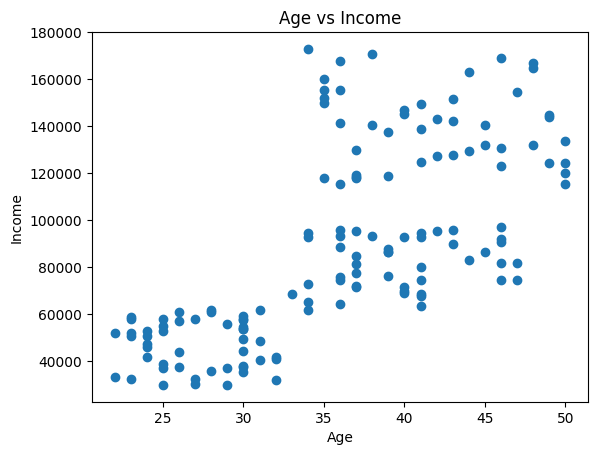

In [5]:
plt.scatter(df["Age"],df["Income"])
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Age vs Income")

Without Feature Scaling 

In [6]:
from sklearn.cluster import KMeans

In [7]:
km=KMeans(n_clusters=3)
pred=km.fit_predict(df[["Age","Income"]])

In [18]:
# km.fit_predict(pred)
pred

array([2, 0, 2, 2, 0, 2, 0, 0, 1, 2, 1, 1, 2, 2, 1, 1, 0, 2, 0, 1, 0, 2,
       1, 0, 1, 0, 0, 2, 1, 1, 0, 2, 2, 0, 0, 0, 1, 2, 0, 1, 0, 2, 0, 1,
       2, 0, 2, 1, 1, 2, 0, 0, 0, 2, 2, 1, 2, 0, 1, 1, 1, 2, 1, 0, 0, 0,
       0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 0, 1, 2, 0, 1, 1, 1, 2, 1, 1, 1, 1,
       0, 0, 2, 2, 0, 2, 2, 1, 1, 0, 2, 1, 2, 2, 1, 0, 0, 1, 0, 1, 1, 0,
       1, 2, 0, 1, 0, 2, 1, 0, 2, 1, 0, 1, 0, 2, 1, 2, 0, 0, 1, 1, 0, 0,
       0, 1, 1, 2, 0, 2, 2, 1], dtype=int32)

In [19]:
df["Cluster"]=pred

In [20]:
df

,Age,Income,Cluster
0,36,88500,2
1,30,38000,0
2,41,80000,2
3,43,96000,2
4,24,53000,0
...,...,...,...
135,37,72000,2
136,30,54000,0
137,40,70000,2
138,37,81500,2


In [21]:
df1=df[df.Cluster==0]
df2=df[df.Cluster==1]
df3=df[df.Cluster==2]


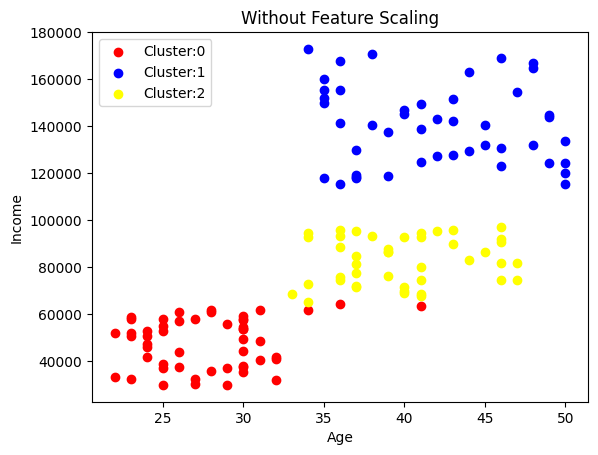

In [55]:
plt.scatter(df1["Age"],df1["Income"],color="red",label="Cluster:0")
plt.scatter(df2["Age"],df2["Income"],color="blue",label="Cluster:1")
plt.scatter(df3["Age"],df3["Income"],color="yellow",label="Cluster:2")
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Without Feature Scaling")
plt.legend()
plt.show()

With Feature Scaling


In [23]:
from sklearn.preprocessing import MinMaxScaler

In [24]:
ms=MinMaxScaler()


In [56]:
scaler=ms.fit_transform(df[["Age","Income"]])

In [57]:
scaler

array([[0.5       , 0.40909091],
       [0.28571429, 0.05594406],
       [0.67857143, 0.34965035],
       [0.75      , 0.46153846],
       [0.07142857, 0.16083916],
       [0.64285714, 0.27272727],
       [0.28571429, 0.19230769],
       [0.14285714, 0.05244755],
       [0.82142857, 0.71328671],
       [0.60714286, 0.3951049 ],
       [0.46428571, 0.83916084],
       [0.53571429, 0.61538462],
       [0.67857143, 0.45104895],
       [0.42857143, 0.44055944],
       [0.5       , 0.77972028],
       [0.96428571, 0.66083916],
       [0.10714286, 0.04895105],
       [0.53571429, 0.33216783],
       [0.25      , 0.18181818],
       [0.64285714, 0.80769231],
       [0.28571429, 0.13636364],
       [0.89285714, 0.31118881],
       [0.96428571, 0.7972028 ],
       [0.35714286, 0.08391608],
       [0.5       , 0.87762238],
       [0.17857143, 0.1958042 ],
       [0.32142857, 0.07342657],
       [0.85714286, 0.43356643],
       [0.67857143, 0.76223776],
       [0.78571429, 0.6958042 ],
       [0.

In [58]:
df_sceler=pd.DataFrame(scaler,columns=["Age","Income"])

In [59]:
df_sceler

,Age,Income
0,0.500000,0.409091
1,0.285714,0.055944
2,0.678571,0.349650
3,0.750000,0.461538
4,0.071429,0.160839
...,...,...
135,0.535714,0.293706
136,0.285714,0.167832
137,0.642857,0.279720
138,0.535714,0.360140


In [60]:
kms=KMeans(n_clusters=3)
pre_scl=kms.fit_predict(df_sceler[["Age","Income"]])

In [31]:
df_sceler["Cluster_Scaler"]=pre_scl

In [32]:
df_sceler


,Age,Income,Cluster_Scaler
0,0.500000,0.409091,1
1,0.285714,0.055944,0
2,0.678571,0.349650,1
3,0.750000,0.461538,1
4,0.071429,0.160839,0
...,...,...,...
135,0.535714,0.293706,1
136,0.285714,0.167832,0
137,0.642857,0.279720,1
138,0.535714,0.360140,1


Text(0, 0.5, 'Income')

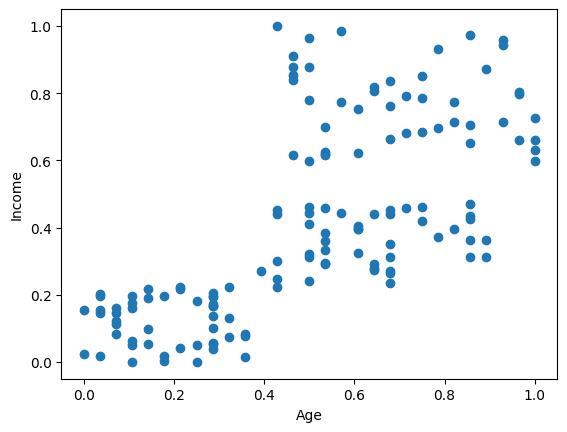

In [33]:
plt.scatter(df_sceler["Age"],df_sceler["Income"])
plt.xlabel("Age")
plt.ylabel("Income")

In [34]:
df4=df_sceler[df_sceler.Cluster_Scaler==0]
df5=df_sceler[df_sceler.Cluster_Scaler==1]
df6=df_sceler[df_sceler.Cluster_Scaler==2]



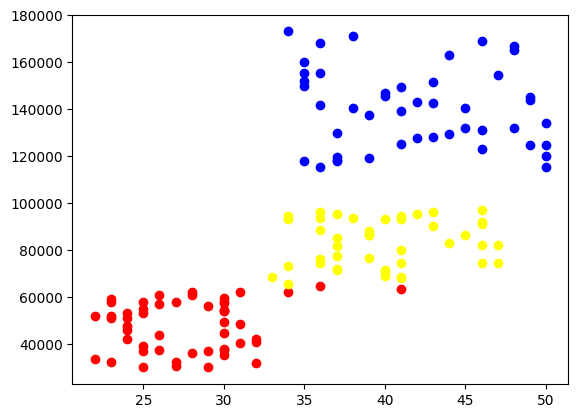

In [48]:
plt.scatter(df1["Age"],df1["Income"],color="red",label="Cluster:0")
plt.scatter(df2["Age"],df2["Income"],color="blue",label="Cluster:1")
plt.scatter(df3["Age"],df3["Income"],color="yellow",label="Cluster:2")


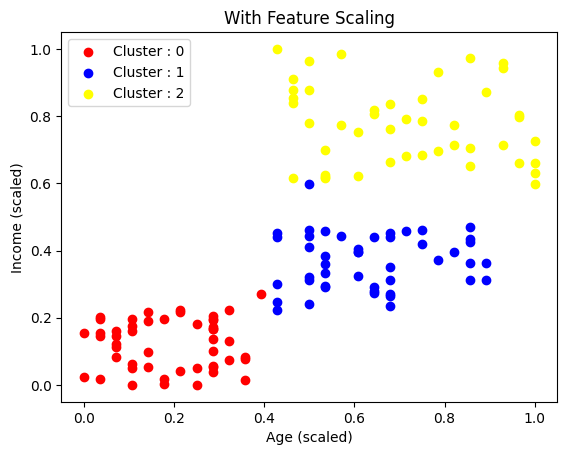

In [61]:
plt.scatter(df4["Age"],df4["Income"],color="red",label="Cluster : 0")
plt.scatter(df5["Age"],df5["Income"],color="blue",label="Cluster : 1")
plt.scatter(df6["Age"],df6["Income"],color="yellow",label="Cluster : 2")
plt.xlabel("Age (scaled)")
plt.ylabel("Income (scaled)")
plt.title("With Feature Scaling")
plt.legend()
plt.show()

In [50]:
wcss=[]
for i in range(1,11):
    kmr=KMeans(n_clusters=i)
    kmr.fit_predict(df_sceler[["Age","Income"]])
    wcss.append(kmr.inertia_)
    

In [51]:
wcss

[21.90819714394354,
 7.804747301975107,
 4.17328316123977,
 3.297055035222577,
 2.3169262241038706,
 2.2001867035323004,
 1.55588794372333,
 1.4489017912676143,
 1.2279054695071792,
 1.0886343368489857]

Elbow Garph repersentaion

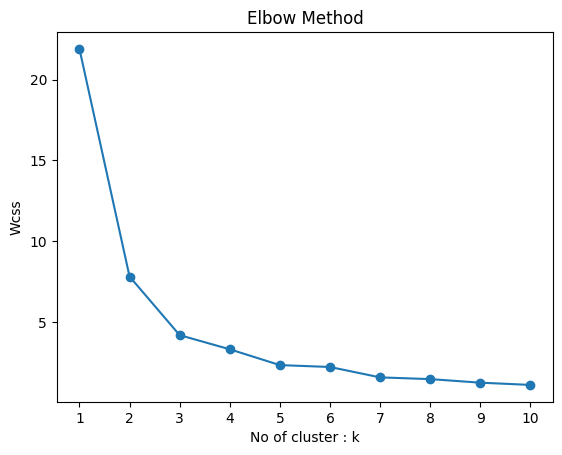

In [65]:
plt.plot(range(1,11),wcss,marker="o")

plt.xlabel("No of cluster : k")
plt.ylabel("Wcss")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [66]:
kmr.cluster_centers_

array([[0.69642857, 0.77372627],
       [0.08095238, 0.16853147],
       [0.65873016, 0.28865579],
       [0.92410714, 0.7611451 ],
       [0.11688312, 0.04100445],
       [0.28896104, 0.12539733],
       [0.80357143, 0.40534466],
       [0.48412698, 0.8986014 ],
       [0.51242236, 0.3618121 ],
       [0.53061224, 0.62787213]])

[[0.71915584 0.77908455]
 [0.18452381 0.11953671]
 [0.6235119  0.37099359]]


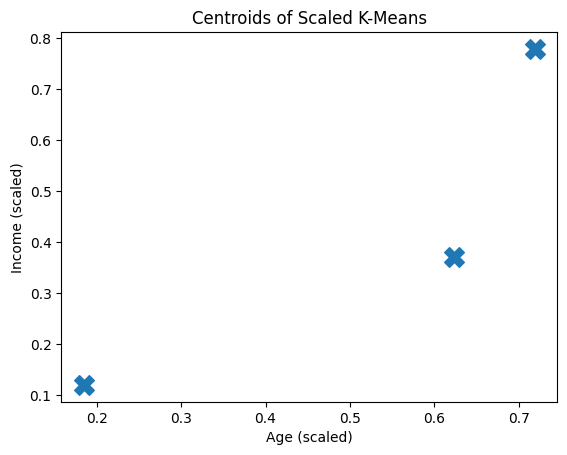

In [67]:
# Centroids from the scaled, three-cluster model
print(kms.cluster_centers_)

plt.scatter(
    kms.cluster_centers_[:, 0],
    kms.cluster_centers_[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Age (scaled)")
plt.ylabel("Income (scaled)")
plt.title("Centroids of Scaled K-Means")
plt.show()